# NF-κB (p65) Transcription Factor Assay — analysis, figure and PDF report

Cayman kit 10007889, Epoch 2, OD450. Rhein 60 µM vs NaOH vehicle, n = 6 per group, duplicate wells.

**How to use**
1. Run all cells (`Runtime ▸ Run all`). By default it uses the plate values from the 24-Jun-2025 run (embedded below).
2. To analyse a new plate, either edit the `PLATE` dictionary in cell 2, or set `USE_UPLOAD = True` and upload the raw Gen5 `.xlsx` export when prompted (the parser looks for the 8 × N block under the row/column headers).
3. Edit `SAMPLES` to match your well map.
4. Outputs: `NFkB_figure.pdf` / `.png` (the figure alone) and `NFkB_report.pdf` (figure + tables) — downloaded automatically at the end.

In [ ]:
#@title 1 · Setup
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy import stats
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42})   # editable text in Illustrator
print('ok')

ok


In [ ]:
#@title 2 · Input: raw plate and well map
USE_UPLOAD = False          #@param {type:"boolean"}

# Raw OD450 as exported by Gen5 (rows A–H, columns 1–6). Replace or upload.
PLATE = {
 'A':[0.047,0.250,0.200,0.233,0.221,0.310],
 'B':[0.881,0.179,0.160,0.226,0.235,0.310],
 'C':[0.440,0.199,0.158,0.264,0.291,0.325],
 'D':[0.241,0.201,0.145,0.209,0.238,0.313],
 'E':[0.142,0.168,0.143,0.302,0.452,0.297],
 'F':[0.093,0.169,0.135,0.324,0.409,0.261],
 'G':[0.075,0.257,0.219,0.335,0.524,0.249],
 'H':[0.061,0.221,0.207,0.330,0.361,0.232]}

if USE_UPLOAD:
    from google.colab import files
    up = files.upload(); fname = next(iter(up))
    raw = pd.read_excel(fname, header=None)
    # find the row whose 3rd cell is 1 and next rows start with 'A'..'H'
    for i in range(len(raw)):
        if raw.iloc[i, 2] == 1 and str(raw.iloc[i+1, 1]).strip() == 'A':
            hdr = i; break
    ncol = int(raw.iloc[hdr, 2:].dropna().max())
    PLATE = {str(raw.iloc[hdr+1+k, 1]).strip(): [float(v) for v in raw.iloc[hdr+1+k, 2:2+ncol]] for k in range(8)}
    print('parsed plate from', fname)

plate = pd.DataFrame(PLATE, index=range(1, len(PLATE['A'])+1)).T   # rows A–H, cols 1..N
display(plate)

BLANK_WELL = 'A1'    # no antibody (substrate background)
ZERO_WELL  = 'H1'    # buffer + antibodies = non-specific binding  (kit-recommended for samples)
BACKGROUND = 'zero'  #@param ["zero", "blank"]
PC_WELLS   = ['B1','C1','D1','E1','F1','G1']   # positive control 1:1 … 1:32

# Well map: sample -> (group, wells). Control group must be first in GROUP_ORDER.
SAMPLES = {
 'Ctrl 1':('Control',['G2','G3']), 'Ctrl 2':('Control',['H2','H3']), 'Ctrl 3':('Control',['A4','A5']),
 'Ctrl 4':('Control',['B4','B5']), 'Ctrl 5':('Control',['C4','C5']), 'Ctrl 6':('Control',['D4','D5']),
 'Rhein 1':('Rhein 60 µM',['A2','A3']), 'Rhein 2':('Rhein 60 µM',['B2','B3']), 'Rhein 3':('Rhein 60 µM',['C2','C3']),
 'Rhein 4':('Rhein 60 µM',['D2','D3']), 'Rhein 5':('Rhein 60 µM',['E2','E3']), 'Rhein 6':('Rhein 60 µM',['F2','F3']),
}
GROUP_ORDER = ['Control', 'Rhein 60 µM']
Y_LABEL = 'NF-κB p65 DNA binding\n(% of control)'
NORMALISE_TO_CONTROL = True   # False -> plot background-corrected OD450 instead of %

,1,2,3,4,5,6
A,0.047,0.250,0.200,0.233,0.221,0.310
B,0.881,0.179,0.160,0.226,0.235,0.310
C,0.440,0.199,0.158,0.264,0.291,0.325
D,0.241,0.201,0.145,0.209,0.238,0.313
E,0.142,0.168,0.143,0.302,0.452,0.297
F,0.093,0.169,0.135,0.324,0.409,0.261
G,0.075,0.257,0.219,0.335,0.524,0.249
H,0.061,0.221,0.207,0.330,0.361,0.232


In [ ]:
#@title 3 · Background correction, per-sample table, group statistics
od = lambda w: plate.loc[w[0], int(w[1:])]
bg = od(ZERO_WELL) if BACKGROUND == 'zero' else od(BLANK_WELL)

rows = []
for s, (g, wells) in SAMPLES.items():
    v = np.array([od(w) for w in wells])
    rows.append(dict(sample=s, group=g, wells='/'.join(wells), od1=v[0], od2=v[-1], mean_od=v.mean(),
                     dup_cv=v.std(ddof=1)/v.mean()*100 if len(v)>1 else np.nan, corrected=v.mean()-bg))
df = pd.DataFrame(rows)
ctrl_mean = df.loc[df.group==GROUP_ORDER[0], 'corrected'].mean()
df['pct_control'] = df.corrected/ctrl_mean*100
df['value'] = df.pct_control if NORMALISE_TO_CONTROL else df.corrected
display(df.round(3))

ctrl = df.loc[df.group==GROUP_ORDER[0], 'value'].values
trt  = df.loc[df.group==GROUP_ORDER[1], 'value'].values
welch = stats.ttest_ind(trt, ctrl, equal_var=False)
student = stats.ttest_ind(trt, ctrl, equal_var=True)
mwu = stats.mannwhitneyu(trt, ctrl, alternative='two-sided')
d = (ctrl.mean()-trt.mean())/np.sqrt((ctrl.var(ddof=1)+trt.var(ddof=1))/2)
summary = pd.DataFrame({
  'n':[len(ctrl), len(trt)], 'mean':[ctrl.mean(), trt.mean()], 'SD':[ctrl.std(ddof=1), trt.std(ddof=1)],
  'SEM':[stats.sem(ctrl), stats.sem(trt)], 'CV %':[ctrl.std(ddof=1)/ctrl.mean()*100, trt.std(ddof=1)/trt.mean()*100]},
  index=GROUP_ORDER)
tests = pd.Series({'background subtracted (OD)': bg, 'control mean corrected OD': ctrl_mean,
   '% of control (treatment)': trt.mean()/ctrl.mean()*100, '% inhibition': 100-trt.mean()/ctrl.mean()*100,
   'Welch t p': welch.pvalue, 'Student t p': student.pvalue, 'Mann-Whitney U p': mwu.pvalue, "Cohen's d": d})
display(summary.round(3)); display(tests.round(4))

# positive-control curve
pc = np.array([od(w) for w in PC_WELLS]) - bg
dil = 1/2**np.arange(len(PC_WELLS))
fit = stats.linregress(dil, pc)
print(f'PC curve: slope {fit.slope:.3f}, R² {fit.rvalue**2:.4f}; samples at {ctrl_mean/fit.slope*100:.0f}% (ctrl) and {trt.mean()*ctrl_mean/100/fit.slope*100 if NORMALISE_TO_CONTROL else trt.mean()/fit.slope*100:.0f}% (trt) of PC1')

,sample,group,wells,od1,od2,mean_od,dup_cv,corrected,pct_control,value
0,Ctrl 1,Control,G2/G3,0.257,0.219,0.238,11.290,0.177,101.675,101.675
1,Ctrl 2,Control,H2/H3,0.221,0.207,0.214,4.626,0.153,87.889,87.889
2,Ctrl 3,Control,A4/A5,0.233,0.221,0.227,3.738,0.166,95.357,95.357
3,Ctrl 4,Control,B4/B5,0.226,0.235,0.230,2.761,0.169,97.367,97.367
4,Ctrl 5,Control,C4/C5,0.264,0.291,0.277,6.880,0.216,124.366,124.366
5,Ctrl 6,Control,D4/D5,0.209,0.238,0.223,9.175,0.162,93.346,93.346
6,Rhein 1,Rhein 60 µM,A2/A3,0.250,0.200,0.225,15.713,0.164,94.208,94.208
7,Rhein 2,Rhein 60 µM,B2/B3,0.179,0.160,0.169,7.926,0.108,62.326,62.326
8,Rhein 3,Rhein 60 µM,C2/C3,0.199,0.158,0.178,16.242,0.118,67.496,67.496
9,Rhein 4,Rhein 60 µM,D2/D3,0.201,0.145,0.173,22.889,0.112,64.337,64.337


,n,mean,SD,SEM,CV %
Control,6,100.000,12.775,5.215,12.775
Rhein 60 µM,6,65.821,15.097,6.163,22.937


,0
background subtracted (OD),0.0610
control mean corrected OD,0.1741
% of control (treatment),65.8210
% inhibition,34.1790
Welch t p,0.0018
Student t p,0.0017
Mann-Whitney U p,0.0087
Cohen's d,2.4441


PC curve: slope 0.834, R² 0.9990; samples at 21% (ctrl) and 14% (trt) of PC1


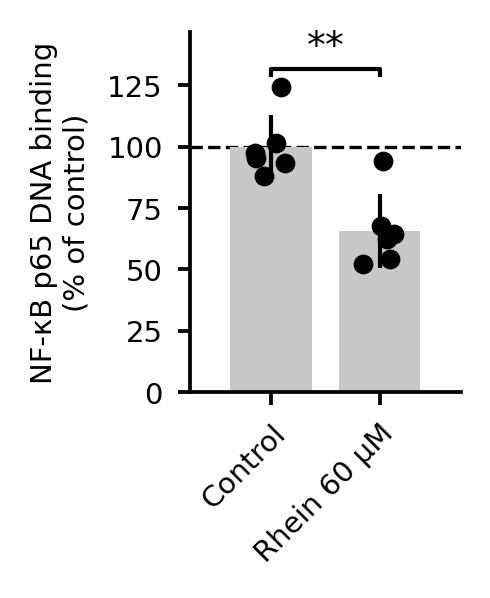

Welch p = 0.0018  ->  **


In [ ]:
#@title 4 · Figure (grey bar, black points, mean ± SD, significance bracket)
def stars(p):
    return '****' if p<1e-4 else '***' if p<1e-3 else '**' if p<1e-2 else '*' if p<0.05 else 'ns'

def bar_dot_plot(groups, values, ylabel, p, ax=None, bar_color='#C8C8C8', dot_color='black',
                 err='sd', ref_line=None, jitter=0.09, seed=0, bar_w=0.45, gap=0.15):
    """Style of the reference panel: grey filled bar = mean, black dots = individual values,
    black error bar = SD (or SEM), open left/bottom spines only, 45° labels, bracket with stars."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(FIG_W_CM/2.54, FIG_H_CM/2.54), dpi=300)
    rng = np.random.default_rng(seed)
    xpos = np.arange(len(groups)) * (bar_w + gap)     # bar centres
    for i, (g, v) in enumerate(zip(groups, values)):
        x = xpos[i]
        e = v.std(ddof=1) if err=='sd' else stats.sem(v)
        ax.bar(x, v.mean(), width=bar_w, color=bar_color, edgecolor='none', zorder=1)
        ax.errorbar(x, v.mean(), yerr=e, color=dot_color, lw=1.0, capsize=0, zorder=2)
        ax.scatter(x + rng.uniform(-jitter, jitter, len(v)), v, s=14, color=dot_color, zorder=3, clip_on=False)
    ax.set_xticks(xpos); ax.set_xticklabels(groups, rotation=45, ha='right', rotation_mode='anchor')
    ax.set_ylabel(ylabel)
    for sp in ('top','right'): ax.spines[sp].set_visible(False)
    for sp in ('left','bottom'): ax.spines[sp].set_linewidth(0.9)
    ax.tick_params(width=0.9, length=3)
    ax.set_xlim(xpos[0]-bar_w, xpos[-1]+bar_w)
    if ref_line is not None:
        ax.axhline(ref_line, ls='--', color='black', lw=0.8, zorder=0)
    # bracket
    top = max(v.max() for v in values); ymax = top*1.18
    ax.set_ylim(0, ymax)
    y = top*1.06; h = top*0.02
    ax.plot([xpos[0]]*2+[xpos[1]]*2,[y-h,y,y,y-h], color='black', lw=1.0)
    ax.text(xpos[:2].mean(), y+h*0.5, stars(p), ha='center', va='bottom', fontsize=9)
    return ax

FIG_W_CM, FIG_H_CM = 4.1, 5.0      # final panel size in cm (page size of the PDF)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':7, 'axes.labelsize':7, 'xtick.labelsize':7, 'ytick.labelsize':7})
ax = bar_dot_plot(GROUP_ORDER, [ctrl, trt], Y_LABEL, welch.pvalue, ref_line=100 if NORMALISE_TO_CONTROL else None)
# fixed margins so the PDF page is exactly FIG_W_CM x FIG_H_CM (no bbox='tight', which would resize the page)
plt.gcf().subplots_adjust(left=0.40, right=0.96, bottom=0.34, top=0.95)
plt.savefig('NFkB_figure.pdf'); plt.savefig('NFkB_figure.png')
plt.show()
print(f'Welch p = {welch.pvalue:.4f}  ->  {stars(welch.pvalue)}')

In [ ]:
#@title 5 · PDF report (figure + tables) and download
import datetime
with PdfPages('NFkB_report.pdf') as pdf:
    # page 1: title, methods, figure
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(0.08, 0.95, 'NF-κB (p65) Transcription Factor Assay — Rhein 60 µM vs vehicle', fontsize=14, weight='bold')
    meta = (f'Generated {datetime.date.today():%d %b %Y}. Cayman kit 10007889, OD450 (Epoch 2). '
            f'Background subtracted: {BACKGROUND} well ({bg:.3f} OD). Values are mean of duplicate wells, '
            f'{"expressed as % of control mean" if NORMALISE_TO_CONTROL else "background-corrected OD450"}.\n'
            f'n = {len(ctrl)} vs {len(trt)}. Bars = mean, error = SD, points = individual samples. '
            f'Welch two-tailed t-test: p = {welch.pvalue:.4f} ({stars(welch.pvalue)}). '
            f'Mann-Whitney U: p = {mwu.pvalue:.4f}. Cohen\'s d = {d:.2f}. '
            f'Treatment = {trt.mean()/ctrl.mean()*100:.1f}% of control ({100-trt.mean()/ctrl.mean()*100:.1f}% inhibition).')
    import textwrap
    fig.text(0.08, 0.93, textwrap.fill(meta, 110), fontsize=8.5, va='top', linespacing=1.5)
    ax = fig.add_axes([0.20, 0.42, 0.22, 0.36])
    bar_dot_plot(GROUP_ORDER, [ctrl, trt], Y_LABEL, welch.pvalue, ax=ax, ref_line=100 if NORMALISE_TO_CONTROL else None)
    # summary table
    ax2 = fig.add_axes([0.50, 0.55, 0.42, 0.20]); ax2.axis('off')
    t = ax2.table(cellText=summary.round(2).astype(object).assign(n=summary.n.astype(int)).values, rowLabels=summary.index, colLabels=summary.columns, loc='center', cellLoc='center')
    t.auto_set_font_size(False); t.set_fontsize(8); t.scale(1, 1.4)
    ax2.set_title('Group statistics', fontsize=9, loc='left')
    # PC curve
    ax3 = fig.add_axes([0.55, 0.10, 0.35, 0.25])
    ax3.scatter(dil, pc, color='black', s=20); xs=np.linspace(0,1,50); ax3.plot(xs, fit.intercept+fit.slope*xs, color='grey', lw=1)
    ax3.axhline(ctrl_mean, ls=':', color='black', lw=0.8); ax3.text(0.98, ctrl_mean, 'control mean ', fontsize=7, va='bottom', ha='right')
    ax3.set_xlabel('PC dilution (fraction of PC1)', fontsize=8); ax3.set_ylabel('corrected OD450', fontsize=8)
    ax3.set_title(f'Positive-control curve  R² = {fit.rvalue**2:.3f}', fontsize=9, loc='left'); ax3.tick_params(labelsize=7)
    for sp in ('top','right'): ax3.spines[sp].set_visible(False)
    pdf.savefig(fig); plt.close(fig)
    # page 2: per-sample table
    fig = plt.figure(figsize=(8.27, 11.69)); fig.text(0.08, 0.95, 'Per-sample values', fontsize=12, weight='bold')
    ax = fig.add_axes([0.05, 0.40, 0.90, 0.50]); ax.axis('off')
    cols = ['sample','group','wells','od1','od2','mean_od','dup_cv','corrected','pct_control']
    t = ax.table(cellText=df[cols].round(3).values, colLabels=['Sample','Group','Wells','OD 1','OD 2','Mean OD','Dup. CV %','Corrected OD','% control'], loc='upper center', cellLoc='center')
    t.auto_set_font_size(False); t.set_fontsize(8); t.scale(1, 1.4)
    fig.text(0.08, 0.35, textwrap.fill('Tests: ' + '; '.join(f'{k} = {v:.4g}' for k, v in tests.items()), 110), fontsize=8.5, va='top', linespacing=1.5)
    pdf.savefig(fig); plt.close(fig)
df.to_csv('NFkB_per_sample.csv', index=False)
print('written: NFkB_report.pdf, NFkB_figure.pdf/.png, NFkB_per_sample.csv')
try:
    from google.colab import files
    for f in ['NFkB_report.pdf', 'NFkB_figure.pdf', 'NFkB_figure.png', 'NFkB_per_sample.csv']: files.download(f)
except ImportError:
    pass

written: NFkB_report.pdf, NFkB_figure.pdf/.png, NFkB_per_sample.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>